# MC-IM SiO2 data

In [3]:

%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-calcs.py
%run -i scripts/intersection.py # intersection function
%run -i scripts/odr_models.py # ODR and model functions 
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'QTZ-'


In [4]:
from dataclasses import dataclass, field, fields
import scipy as sp
from scipy import linalg
from copy import deepcopy
# for customizing colors
from cycler import cycler

# https://realpython.com/python-data-classes/
@dataclass
class HPeos_MC:
    """ Data class for Monte-Carlo Hugoniot Uncertainties.
        sts 2025-07-24
    """
    npts:        int = 0      # number of MC points for each independent up
    up_ind:      np.ndarray = field(default_factory=lambda: np.zeros(0)) # independent up
    rho0:        np.ndarray = field(default_factory=lambda: np.zeros(0))  
    up:          np.ndarray = field(default_factory=lambda: np.zeros(0))
    us:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho:         np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho0_mean:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_mean:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_mean:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    rho0_std:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_std:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_std:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    def __iter__(self):
        '''Needed to convert class object into dictionary.'''
        for key in self.__dict__:
            yield key, getattr(self,key)
    def calcPrho(self):
        ''' Calculate pressure and density values from particle velocity and shock velocity values. No error propagation. '''
        self.p = self.rho0 * self.us * self.up
        self.rho = 1./( (1./self.rho0) * (1. - self.up/self.us) )
    def calcMC(self,upus_fit,ust_fit,verbose=True):
        ''' Calculate MC uncertainties from up-us and us-temp fits. '''

        # need to be set prior to calling calcMC
        if self.npts == 0:
            print('Need to set number of MC points for each independent up.')
            return
        if len(self.up_ind) == 0:
            print('Need to define independent array for up.')
            return

        nupind = len(self.up_ind)
        nsteps = self.npts
        if verbose:
            print('*** Starting Monte-Carlo uncertainty calculation ***')
            print('Number of particle velocity points = ',nupind)
            print('Number of MC iterations for each up = ',nsteps)
        count=0
        if nupind > 10:
            i_print = np.round(nupind/10) # print about 10 diagnostic steps per run
        ###========================================================================
        # BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS
        
        # us-up fit
        # The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
        dat_lmat_upus = sp.linalg.cholesky(upus_fit.cov,lower=True) 
        dat_lmat_ust = sp.linalg.cholesky(ust_fit.cov,lower=True) 
        
        self.us_mean   = np.zeros(nupind)
        self.p_mean    = np.zeros(nupind)
        self.rho_mean  = np.zeros(nupind)
        self.rho0_mean  = np.zeros(nupind)
        self.t_mean    = np.zeros(nupind)
        self.us_std   = np.zeros(nupind)
        self.p_std    = np.zeros(nupind)
        self.rho_std  = np.zeros(nupind)
        self.rho0_std  = np.zeros(nupind)
        self.t_std    = np.zeros(nupind)

        if verbose:
            print('Monte-Carlo error bar calculation using these us-up and us-temp fits:')
            print(upus_fit.filename)
            print('Coefs = ',upus_fit.a)
            print(ust_fit.filename)
            print('Coefs = ',ust_fit.a)
        
        # loop over independent variable up
        for iup in range(len(self.up_ind)):
            # set independent variable
            self.up   = np.zeros(nsteps)+self.up_ind[iup]
            # set up MC variables
            self.rho0 = np.zeros(nsteps)
            self.us   = np.zeros(nsteps)
            self.p    = np.zeros(nsteps)
            self.rho  = np.zeros(nsteps)
            self.t    = np.zeros(nsteps)
        
            # MC steps for each independent variable
            temp_fit = hp.HPeos_Fit()
        
            # up -> Us, P, V points
            # Us -> T points
            for imc in range(nsteps):      
                # uncertainty on initial density
                self.rho0[imc] = upus_fit.rho_ref + upus_fit.rho_ref_std*np.random.randn()
        
                # uncertainty on curve fit to us-up
                ncoefs = len(upus_fit.a)
                temp_mat=np.random.randn(ncoefs)
                bmat=np.matmul(dat_lmat_upus,temp_mat)
                
                a_mc = np.zeros(ncoefs)
                for ia in range(ncoefs):
                    a_mc[ia] = upus_fit.a[ia]+bmat[ia]
                # fill generic fit data structure
                temp_fit.a = a_mc
                temp_fit.curvetype = upus_fit.curvetype
                self.us[imc]=temp_fit.calcf(self.up[imc])
                #print(temp_fit.a)
        
                # uncertainty on curve fit to T-us
                ncoefs = len(ust_fit.a)
                temp_mat=np.random.randn(ncoefs)
                bmat=np.matmul(dat_lmat_ust,temp_mat)
                
                a_mc = np.zeros(ncoefs)
                for ia in range(ncoefs):
                    a_mc[ia] = ust_fit.a[ia]+bmat[ia]
                # fill generic fit data structure
                temp_fit.a = a_mc
                temp_fit.curvetype = ust_fit.curvetype
                self.t[imc]=temp_fit.calcf(self.us[imc])
                #print(temp_fit.a)
                
            # for each independent variable
            # calculate P and rho for the MC batch
            self.calcPrho()
            # The mean and std for each MC batch
            self.rho0_mean[iup] = np.mean(self.rho0)
            self.rho0_std[iup] = np.std(self.rho0)
            self.us_mean[iup] = np.mean(self.us)
            self.us_std[iup] = np.std(self.us)
            self.p_mean[iup] = np.mean(self.p)
            self.p_std[iup] = np.std(self.p)
            self.rho_mean[iup] = np.mean(self.rho)
            self.rho_std[iup] = np.std(self.rho)
            self.t_mean[iup] = np.mean(self.t)
            self.t_std[iup] = np.std(self.t)


            if verbose:
                # print about 10 diagnostic steps per run
                if (count % i_print) == 0:
                    print(count,self.up_ind[iup],self.us_mean[iup],self.us_std[iup],upus_fit.calcf(self.up_ind[iup]),self.rho0_mean[iup],self.rho0_std[iup],self.p_mean[iup],self.rho_mean[iup],self.t_mean[iup],self.t_std[iup])
                count += 1
        if 1:
            # free up memory
            steps = 1
            self.rho0 = np.zeros(steps)
            self.us   = np.zeros(steps)
            self.p    = np.zeros(steps)
            self.rho  = np.zeros(steps)
            self.t    = np.zeros(steps)
@dataclass
class HPeos_MCIM:
    """ Data class for Monte-Carlo Impedance Match Uncertainties.
        sts 2025-08-29
    """
    npts:        int = 0      # number of MC points for each independent up
    up_ind:      np.ndarray = field(default_factory=lambda: np.zeros(0)) # independent up
    # target variables
    rho0:        np.ndarray = field(default_factory=lambda: np.zeros(0))  
    up:          np.ndarray = field(default_factory=lambda: np.zeros(0))
    us:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho:         np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t:           np.ndarray = field(default_factory=lambda: np.zeros(0))
    # flyer variables
    a_vi:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_rho0:        np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_up:          np.ndarray = field(default_factory=lambda: np.zeros(0))
    a_us:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_p:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_rho:         np.ndarray = field(default_factory=lambda: np.zeros(0))  
    # match state in target
    up_all:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_all:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_all:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_all:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_all:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    up_mean:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_mean:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_mean:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    up_std:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_std:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_std:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    def __iter__(self):
        '''Needed to convert class object into dictionary.'''
        for key in self.__dict__:
            yield key, getattr(self,key)
    def calcPrho(self):
        ''' Calculate pressure and density values from particle velocity and shock velocity values. No error propagation. '''
        self.p = self.rho0 * self.us * self.up
        self.rho = 1./( (1./self.rho0) * (1. - self.up/self.us) )
        self.a_p = self.a_rho0 * self.a_us * self.a_up
        self.a_rho = 1./( (1./self.a_rho0) * (1. - self.a_up/self.a_us) )

    def calcIM(self,upus_fit1,upus_fit2,ust_fit2,vi,vi_std,verbose=True):
        ''' Calculate IM MC uncertainties from up-us fits; optional us-temp fits for target. '''

        # need to be set prior to calling calcMC
        if self.npts == 0:
            print('Need to set number of MC iterations of vi.')
            return
        if len(self.up_ind) == 0:
            print('Need to define independent array for up.')
            return

        nupind = len(self.up_ind)
        nsteps = self.npts
        if verbose:
            print('*** Starting Monte-Carlo uncertainty calculation ***')
            print('Number of particle velocity points = ',nupind)
            print('Number of MC iterations of vi = ',nsteps)
        count=0
        if nupind > 10:
            i_print = np.round(nupind/10) # print about 10 diagnostic steps per run
        ###========================================================================
        # BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS
        
        # us-up fit
        # The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
        dat_lmat_upus1 = sp.linalg.cholesky(upus_fit1.cov,lower=True) 
        dat_lmat_upus2 = sp.linalg.cholesky(upus_fit2.cov,lower=True) 
        dat_lmat_ust2 = sp.linalg.cholesky(ust_fit2.cov,lower=True) 

        # IM state arrays
        self.a_vi     = np.zeros(nsteps)
        self.up_all   = np.zeros(nsteps)
        self.us_all   = np.zeros(nsteps)
        self.p_all    = np.zeros(nsteps)
        self.rho_all  = np.zeros(nsteps)
        self.t_all    = np.zeros(nsteps)
        self.rho0     = np.zeros(nsteps)
        self.a_rho0   = np.zeros(nsteps)

        if verbose:
            print('Monte-Carlo IM calculation using these us-up and us-temp fits:')
            print(upus_fit1.filename)
            print('Coefs1 = ',upus_fit1.a)
            print(upus_fit2.filename)
            print('Coefs2 = ',upus_fit2.a)
            print(ust_fit2.filename)
            print('Coefs2 = ',ust_fit2.a)
        
        # loop over independent variable vi
        for imc in range(nsteps):
            # perturb impact velocity
            self.a_vi[imc] = vi + vi_std*np.random.randn()
            # perturb initial densities
            self.a_rho0   = upus_fit1.rho_ref + upus_fit1.rho_ref_std*np.random.randn()
            self.rho0     = upus_fit2.rho_ref + upus_fit2.rho_ref_std*np.random.randn()
                
            # set independent variable max up needs to be > Vimp
            self.up   = self.up_ind
            # set up Hugoniot instances
            # target
            self.us   = np.zeros(nupind)
            self.p    = np.zeros(nupind)
            self.rho  = np.zeros(nupind)
            self.t    = np.zeros(nupind)
            # flyer
            self.a_us   = np.zeros(nupind)
            self.a_p    = np.zeros(nupind)
            self.a_rho  = np.zeros(nupind)
        
            # MC steps for each independent variable
            temp_fit = hp.HPeos_Fit()

            # vi-up -> Us, P, V points for flyer
            # up -> Us, P, V points for target
            # Us -> T points for target
            # IM intersection states saved for each step

            # flyer Hugoniot Us-Up
            # uncertainty on curve fit to us-up
            ncoefs = len(upus_fit1.a)
            temp_mat=np.random.randn(ncoefs)
            bmat=np.matmul(dat_lmat_upus1,temp_mat)
            
            a_mc = np.zeros(ncoefs)
            for ia in range(ncoefs):
                a_mc[ia] = upus_fit1.a[ia]+bmat[ia]
            # fill generic fit data structure
            temp_fit.a = a_mc
            temp_fit.curvetype = upus_fit1.curvetype
            self.a_us=temp_fit.calcf(self.up_ind)
            self.a_up = self.up_ind
            #print(temp_fit.a)

            # target Hugoniot Us-Up
            # uncertainty on curve fit to us-up
            ncoefs = len(upus_fit2.a)
            temp_mat=np.random.randn(ncoefs)
            bmat=np.matmul(dat_lmat_upus2,temp_mat)
            
            a_mc = np.zeros(ncoefs)
            for ia in range(ncoefs):
                a_mc[ia] = upus_fit2.a[ia]+bmat[ia]
            # fill generic fit data structure
            temp_fit.a = a_mc
            temp_fit.curvetype = upus_fit2.curvetype
            self.us=temp_fit.calcf(self.up_ind)
            self.up=self.up_ind
            #print(temp_fit.a)
    
            # uncertainty on curve fit to T-us
            ncoefs = len(ust_fit2.a)
            temp_mat=np.random.randn(ncoefs)
            bmat=np.matmul(dat_lmat_ust2,temp_mat)
            
            a_mc = np.zeros(ncoefs)
            for ia in range(ncoefs):
                a_mc[ia] = ust_fit2.a[ia]+bmat[ia]
            # fill generic fit data structure
            temp_fit.a = a_mc
            temp_fit.curvetype = ust_fit2.curvetype
            self.t=temp_fit.calcf(self.us)
            #print(temp_fit.a)
                
            # for each independent variable
            # calculate P and rho for mat1 and mat2
            self.calcPrho()

            # calculate the intersection of the P-up Hugoniots
            tmp = vi-self.a_up
            xy=intersection(tmp,self.a_p,self.up,self.p)

            plt.plot(self.up,self.p,'c-')
            plt.plot(tmp,self.a_p,'g-')
        
            # The IM point for each vi instance
            self.up_all[imc] = xy[0]
            self.p_all[imc]  = xy[1]
            self.us_all[imc] = np.interp(xy[0],self.up,self.us)
            self.rho_all[imc] = np.interp(xy[0],self.up,self.rho)
            self.t_all[imc] = np.interp(xy[0],self.up,self.t)
            
            #if verbose:
                # print about 10 diagnostic steps per run
            #    if (count % i_print) == 0:
            #        print(count)
            #    count += 1
        plt.plot(self.up_all,self.p_all,'k.')
        
        # The mean and std for each MC batch
        self.up_mean = np.mean(self.up_all)
        self.up_std = np.std(self.up_all)
        self.us_mean = np.mean(self.us_all)
        self.us_std = np.std(self.us_all)
        self.p_mean = np.mean(self.p_all)
        self.p_std = np.std(self.p_all)
        self.rho_mean = np.mean(self.rho_all)
        self.rho_std = np.std(self.rho_all)
        self.t_mean = np.mean(self.t_all)
        self.t_std = np.std(self.t_all)

        print(self.p_mean,self.up_mean)
        print(self.p_std,self.up_std)

@dataclass
class HPeos_MCIMUS:
    """ Data class for Monte-Carlo Impedance Match Uncertainties.
        sts 2025-08-29
    """
    npts:        int = 0      # number of MC points for each independent up
    up_ind:      np.ndarray = field(default_factory=lambda: np.zeros(0)) # independent up
    # observed variables
    rho0_obs:      float = 0.0
    rho0_obs_std:  float = 0.0
    us_obs:        float = 0.0
    us_obs_std:    float = 0.0
    vi_obs:        float = 0.0
    vi_obs_std:    float = 0.0
    # target variables
    rho0:        float = 0.0
    up:          np.ndarray = field(default_factory=lambda: np.zeros(0))
    us:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho:         np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t:           np.ndarray = field(default_factory=lambda: np.zeros(0))
    # flyer variables
    a_vi:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_rho0:        np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_up:          np.ndarray = field(default_factory=lambda: np.zeros(0))
    a_us:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_p:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    a_rho:         np.ndarray = field(default_factory=lambda: np.zeros(0))  
    # match state in target
    up_all:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_all:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_all:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_all:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_all:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    up_mean:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_mean:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_mean:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    up_std:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_std:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_std:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    def __iter__(self):
        '''Needed to convert class object into dictionary.'''
        for key in self.__dict__:
            yield key, getattr(self,key)
    def calcPrho(self):
        ''' Calculate pressure and density values from particle velocity and shock velocity values. No error propagation. '''
        #self.p = self.rho0 * self.us * self.up
        #self.rho = 1./( (1./self.rho0) * (1. - self.up/self.us) )
        self.a_p = self.a_rho0 * self.a_us * self.a_up
        self.a_rho = 1./( (1./self.a_rho0) * (1. - self.a_up/self.a_us) )

    def calcIMUs(self,upus_fit1,verbose=True):
        ''' Calculate IM MC uncertainties from flyer up-us fit and Us in unknown target '''
        
        # need to be set prior to calling calcMC
        if self.npts == 0:
            print('Need to set number of MC iterations of vi and Us.')
            return
        if len(self.up_ind) == 0:
            print('Need to define independent array for up.')
            return

        nupind = len(self.up_ind)
        nsteps = self.npts
        if verbose:
            print('*** Starting Monte-Carlo uncertainty calculation ***')
            print('Number of particle velocity points = ',nupind)
            print('Number of MC iterations of vi = ',nsteps)
        count=0
        if nupind > 10:
            i_print = np.round(nupind/10) # print about 10 diagnostic steps per run
        ###========================================================================
        # BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS
        
        # us-up fit
        # The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
        dat_lmat_upus1 = sp.linalg.cholesky(upus_fit1.cov,lower=True) 
        #dat_lmat_upus2 = sp.linalg.cholesky(upus_fit2.cov,lower=True) 
        #dat_lmat_ust2 = sp.linalg.cholesky(ust_fit2.cov,lower=True) 

        # IM state arrays
        # flyer
        self.a_vi     = np.zeros(nsteps)
        self.a_rho0   = np.zeros(nsteps)
        # target
        self.rho0_all = np.zeros(nsteps)
        self.up_all   = np.zeros(nsteps)
        self.us_all   = np.zeros(nsteps)
        self.p_all    = np.zeros(nsteps)
        self.rho_all  = np.zeros(nsteps)
        self.t_all    = np.zeros(nsteps)

        if verbose:
            print('Monte-Carlo IM calculation using flyer us-up and target us:')
            print(upus_fit1.filename)
            print('Coefs1 = ',upus_fit1.a)
            #print(upus_fit2.filename)
            #print('Coefs2 = ',upus_fit2.a)
            #print(ust_fit2.filename)
            #print('Coefs2 = ',ust_fit2.a)
        
        # loop over independent variable vi
        for imc in range(nsteps):
            # perturb impact velocity
            self.a_vi[imc] = self.vi_obs + self.vi_obs_std*np.random.randn()
            # perturb shock velocity
            self.us_all[imc] = self.us_obs + self.us_obs_std*np.random.randn()
            # perturb initial densities
            self.a_rho0   = upus_fit1.rho_ref + upus_fit1.rho_ref_std*np.random.randn()
            self.rho0     = self.rho0_obs + self.rho0_obs_std*np.random.randn()
            #print( self.a_rho0, self.rho0,self.rho0_obs)
            # set independent variable max up needs to be > Vimp
            self.up   = self.up_ind
            # target Rayleigh Line
            self.p    = self.rho0*self.us_all[imc]*self.up
            # flyer Hugoniot
            self.a_us   = np.zeros(nupind)
            self.a_p    = np.zeros(nupind)
            self.a_rho  = np.zeros(nupind)
        
            # MC steps for each independent variable
            temp_fit = hp.HPeos_Fit()

            # vi-up -> Us, P, V points for flyer
            # up -> Us, P, V points for target
            # Us -> T points for target
            # IM intersection states saved for each step

            # flyer Hugoniot Us-Up
            # uncertainty on curve fit to us-up
            ncoefs = len(upus_fit1.a)
            temp_mat=np.random.randn(ncoefs)
            bmat=np.matmul(dat_lmat_upus1,temp_mat)
            
            a_mc = np.zeros(ncoefs)
            for ia in range(ncoefs):
                a_mc[ia] = upus_fit1.a[ia]+bmat[ia]
            # fill generic fit data structure
            temp_fit.a = a_mc
            temp_fit.curvetype = upus_fit1.curvetype
            self.a_us=temp_fit.calcf(self.up_ind)
            self.a_up = self.up_ind
            #print(temp_fit.a)
            
            # calculate P and rho for flyer
            self.calcPrho()

            # calculate the intersection of flyer P-up Hugoniot and Target Rayleigh Line
            tmp = self.a_vi[imc]-self.a_up
            xy=intersection(tmp,self.a_p,self.up,self.p)

            plt.plot(self.up,self.p,'c-')
            plt.plot(tmp,self.a_p,'g-')
        
            # The IM point for each vi instance
            self.up_all[imc] = xy[0]
            self.p_all[imc]  = xy[1]
            #self.us_all[imc] = np.interp(xy[0],self.up,self.us)
            self.rho_all[imc] = 1/( (1/self.rho0)*(1-xy[0]/self.us_all[imc]) )
            #self.t_all[imc] = np.interp(xy[0],self.up,self.t)
            
          #  if verbose:
          #      # print about 10 diagnostic steps per run
          #      if (count % i_print) == 0:
          #          print(count)
          #      count += 1
        plt.plot(self.up_all,self.p_all,'k.')
        
        # The mean and std for each MC batch
        self.up_mean = np.mean(self.up_all)
        self.up_std = np.std(self.up_all)
        self.us_mean = np.mean(self.us_all)
        self.us_std = np.std(self.us_all)
        self.p_mean = np.mean(self.p_all)
        self.p_std = np.std(self.p_all)
        self.rho_mean = np.mean(self.rho_all)
        self.rho_std = np.std(self.rho_all)
        self.t_mean = np.mean(self.t_all)
        self.t_std = np.std(self.t_all)

        print(self.p_mean,self.up_mean)
        print(self.p_std,self.up_std)

                                

In [7]:
%run -i scripts/load_im_module

/Users/sts/Library/CloudStorage/Dropbox-Personal/eos/github-group/silica-supplement/silica-book/scripts/IM_module.py:859: SyntaxWarning: invalid escape sequence '\g'
  ax3.plot(1/self.hug.varr/1.e3,self.hug.garr,label='$\gamma(v)$')
/Users/sts/Library/CloudStorage/Dropbox-Personal/eos/github-group/silica-supplement/silica-book/scripts/IM_module.py:860: SyntaxWarning: invalid escape sequence '\g'
  ax3.plot(1/self.hug.varr/1.e3,self.g0*self.hug.varr/self.v0,'--',label='$\gamma_0$/$v_0$=const')


[1497. 2824. 3607. 4730.    0.  232.  339.  529.  659.  745.  889.  969.
 1010. 1057. 1383. 1409. 1409. 1653. 1915. 2334. 2711. 2772.]
[ 6877.  8760.  9980. 11459.  4507.  4925.  5056.  5355.  5577.  5651.
  5891.  6011.  6080.  6152.  6639.  6732.  6734.  7007.  7460.  8054.
  8600.  8667.]
[0.209 0.17  0.239 0.288 0.575 0.97  1.183 1.458 0.597 1.447 1.485] [4.891 4.834 4.936 5.01  5.437 6.025 6.342 6.753 5.47  6.736 6.793]
[0.00224903 0.00227555 0.00243112 0.00419162 0.0029428  0.01493776
 0.0059918  0.05479046 0.00292505 0.00400831 0.00515236]
[1.497 2.824 3.607 4.73  0.232 0.339 0.529 0.659 0.745 0.889 0.969 1.01
 1.057 1.383 1.409 1.409 1.653 1.915 2.334 2.711 2.772 0.209 0.17  0.239
 0.288 0.575 0.97  1.183 1.458 0.597 1.447 1.485]


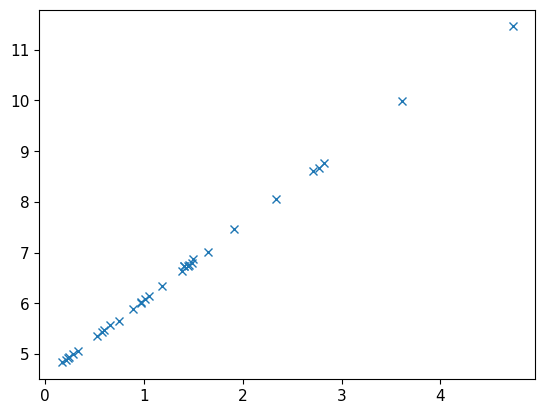

In [31]:
# load the materials data table; change matfilename if not using default
matdata, imat = IM.ReadMaterials(matfilename='imp-match-UCD/materials-data.csv')
# hopefully everything in mks
up =np.arange(101)/100.*10000

mat1 = IM.Material() # create material object named 'mat3'
matname='Steel 304' # material name in the material-data.csv file
mat1.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat1.MakeHugoniot(up)

mat1.GetIHED()
print(mat1.ihed.uparr)
print(mat1.ihed.usarr)
duffy = np.loadtxt('imp-match-UCD/database-user/Duffy-Table6.csv',delimiter=',',skiprows=1)

iup = mat1.ihed.uparr/1.e3
iup_std = iup * .015
ius = mat1.ihed.usarr/1.e3
ius_std = ius * .015
dup = duffy[:,1]
dup_std = duffy[:,2]
dus = duffy[:,3]
dus_std = duffy[:,4]
print(dup,dus)
print(dus_std/dus)

fitx=np.concatenate((iup,dup))
fity=np.concatenate((ius,dus))
fitx_std=np.concatenate((iup_std,dup_std))
fity_std=np.concatenate((ius_std,dus_std))
ind = np.where(fitx>0)
fitx=fitx[ind]
fity=fity[ind]
fitx_std=fitx_std[ind]
fity_std=fity_std[ind]


print(fitx)
plt.plot(fitx,fity,'x')
plt.show()

FIT EOS a =  [4.58102655 1.48725915]
FIT EOS cov =  [[ 6.77654105e-05 -7.84313199e-05]
 [-7.84313199e-05  1.88487536e-04]]
Saved EOS fit in ss304_fit_linear.txt
Saved EOS fit in readable file ss304_fit_linear-readable.txt
rms =  0.03707157939118785


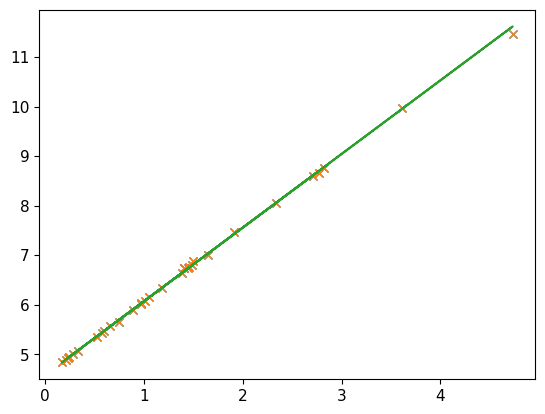

In [33]:

ss304_fit = hp.HPeos_Fit()
ss304_fit.matid = 174
ss304_fit.material = 'Stainless Steel 304'
ss304_fit.rho_ref = 7.87
ss304_fit.rho_ref_units = 'g/cm³'
ss304_fit.x = fitx
ss304_fit.f = fity
ss304_fit.x_std = fitx_std
ss304_fit.f_std = fity_std
ss304_fit.refid = np.zeros(len(fitx))
ss304_fit.reflist = ['test']
ss304_fit.x_var = 'up'
ss304_fit.f_var = 'us'
ss304_fit.x_units = 'km/s'
ss304_fit.f_units = 'km/s'
ss304_fit.x_desc = 'Particle Velocity'
ss304_fit.f_desc = 'Shock Velocity'
DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
ss304_fit.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

ss304_fit.curvetype = 'linear'
ss304_fit.outputfitpath = outputfitpath # in load_paths.py
ss304_fit.filename = 'ss304_fit_linear'
ss304_fit.fit()
print('FIT EOS a = ',ss304_fit.a)
print('FIT EOS cov = ',ss304_fit.cov)
ss304_fit.savejson()
ss304_fit.savereadable()
print('rms = ',ss304_fit.rms)

plt.plot(fitx,fity,'x')
plt.plot(fitx,ss304_fit.a[0]+ss304_fit.a[1]*fitx)
plt.show()

0 4.569 0.101
64.83733707965699 3.2969203846832555
0.09489465667290595 0.0017788147540857414
64.83733707965699
7.419550147012888
0.012420929893508964
Al particle velocity check. High region. 1.2720796153167444


/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_3869/24612258.py:346: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.up_all[imc] = xy[0]
/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_3869/24612258.py:347: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.p_all[imc]  = xy[1]
/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_3869/24612258.py:348: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.us_all[imc] = np.interp(xy[0],sel

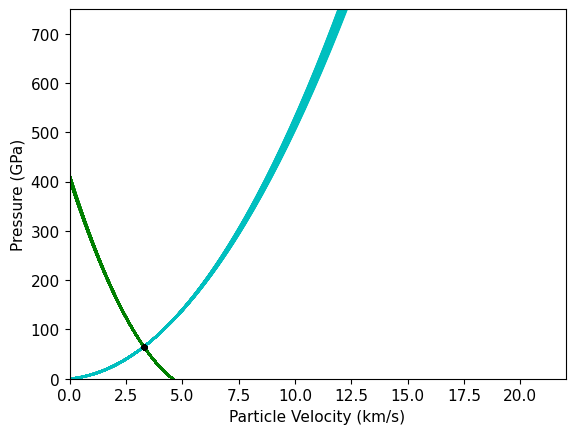

[4.569]
[64.83733708]
[7.42058016]


In [40]:
# shot 27 Vi=4.569 ± 0.101

viarr=[4.569]
viarr_std=[0.101]
nsteps=200
nupind = 200
upmin=0
upmax=25
ppparr = np.zeros(len(viarr))

for iii in range(len(viarr)):
    vi = viarr[iii]
    vi_std = viarr_std[iii]
    print('=========================================')
    print(iii,vi,vi_std)
    
    dat_mc = HPeos_MCIM()
    dat_mc.npts = nsteps
    
    mcuparr = np.linspace(upmin,upmax,nupind)
    dat_mc.up_ind = mcuparr 
    dat_mc.calcIM(ss304_fit,qtz_fit_solid0,qtz_fitTus_solid0,vi,vi_std,verbose=False)

    
    print(dat_mc.p_mean)
    ppparr[iii]=dat_mc.p_mean
    print(dat_mc.us_mean)
    print(dat_mc.us_std)
    print('Al particle velocity check. High region.',vi-dat_mc.up_mean)
plt.ylim(0,750)
plt.xlim(0,22)
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Pressure (GPa)')
plt.show()

print(viarr)
print(ppparr)
print(np.interp(ppparr,qtz_hug_solid.P,qtz_hug_solid.us))